# Filter Data: Sentimen Publik terhadap Raffi Ahmad

**Nama:** Raphael Angelo Adikara Purnama
**NIM:** 164241055
**Mata kuliah:** Natural Language Processing (UAS)
**Topik:** Klasifikasi sentimen publik terhadap Raffi Ahmad setelah kasus "mahasiswa bayaran" di Bundaran HI (29 Oktober 2026)

Notebook ini adalah tahap kedua dari pipeline UAS. Tahap pertama (scraping) sudah menghasilkan JSON mentah dari Apify dan YouTube Data API di `data/01_raw/`, lalu `scraping/to_csv.py` mengubahnya menjadi CSV dengan skema yang sama di `data/02_csv/`. Di notebook ini saya menyaring CSV tersebut sampai siap dilabeli: membuang teks yang tidak bisa dipakai, membuang duplikat dan copy-paste, lalu memfilter akun yang kelihatannya buzzer.

Setiap tahap mencatat berapa baris yang dibuang dan alasannya, jadi tidak ada teks yang hilang tanpa jejak. Semua teks yang dibuang disimpan di `data/03_filtered/dibuang.csv` beserta tahap dan alasannya.

**Revisi setelah konsultasi dosen.** Di versi pertama, gerbang filter membuang teks hanya berdasarkan aturan otomatis. Dosen mengingatkan bahwa aturan seperti "komentar dari pemilik unggahan pasti bukan opini" atau "tweet yang tidak menyebut Raffi pasti tidak relevan" bisa overklaim. Setelah saya cek ulang, kekhawatiran itu benar. Ada balasan pemilik unggahan yang berisi opini, ada tweet relevan yang terbuang karena ditulis dengan huruf unicode tebal, ada tweet berbahasa Indonesia yang diberi kode bahasa Inggris oleh X, dan ada opini asli yang terbuang karena memuat kata "gacor" atau "giveaway". Karena itu di versi ini aturan otomatis hanya menghasilkan **kandidat**. Setiap kandidat dibaca satu per satu, lalu keputusan dan alasannya dicatat di `data/03_filtered/audit/keputusan_manual.csv`. Teks hanya dibuang kalau keputusannya `buang`.

In [1]:
import re
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parent
CSV, OUT, FIG = ROOT / "data" / "02_csv", ROOT / "data" / "03_filtered", ROOT / "figures"
AUDIT = OUT / "audit"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSV / "gabungan.csv", dtype={"parent_id": str, "sumber_id": str})
df["created_at"] = pd.to_datetime(df.created_at, utc=True).dt.tz_convert("Asia/Jakarta")
df["tanggal"] = df.created_at.dt.date
manual = pd.read_csv(AUDIT / "keputusan_manual.csv", dtype=str)
print(df.shape, "| keputusan manual:", len(manual))
df.groupby(["platform", "jalur"]).size().rename("jumlah").to_frame()

(7020, 26) | keputusan manual: 119


jumlah
platform  jalur        
instagram A        1418
          B         571
tiktok    A         834
x         A        2197
youtube   A        2000

Data mentah berisi 7.020 baris dan 26 kolom. X menyumbang 2.197 tweet, Instagram 1.989 komentar (1.418 dari unggahan publik di jalur A dan 571 dari akun Raffi di jalur B), YouTube 2.000 komentar, dan TikTok 834 komentar. Angka ini sudah setelah ID kembar dibuang di `to_csv.py`, karena satu tweet bisa muncul di beberapa query sekaligus.

## Pencatat corong data dan pemeriksaan manual

Supaya jumlah yang dibuang di tiap tahap bisa dilaporkan, saya membuat fungsi kecil `buang()`. Fungsi ini memindahkan baris yang memenuhi syarat ke tabel `dibuang` dengan nama tahap dan alasannya, lalu mencatat sisa baris per platform.

Untuk gerbang yang rawan salah buang (2, 4, dan 5) saya memakai `periksa_manual()`. Aturan otomatis hanya menandai kandidat. Fungsi ini lalu mencocokkan setiap kandidat dengan `keputusan_manual.csv`, menampilkan semua kandidat beserta keputusannya, dan hanya membuang yang diputuskan `buang`. Alasan yang dicatat di `dibuang.csv` adalah alasan manual per teks, bukan alasan umum dari aturannya. Kalau ada kandidat yang belum diperiksa, fungsi ini berhenti dengan error, jadi tidak ada teks yang lolos atau terbuang tanpa dibaca.

In [2]:
dibuang, corong, dipertahankan = [], [], []

def catat(tahap):
    n = df.groupby("platform").size()
    corong.append({"tahap": tahap, **n.to_dict(), "total": int(n.sum())})

def buang(mask, tahap, alasan):
    global df
    mask = mask.reindex(df.index, fill_value=False)
    keluar = df[mask].copy()
    keluar["tahap"], keluar["alasan"] = tahap, alasan if isinstance(alasan, str) else alasan[mask]
    dibuang.append(keluar)
    df = df[~mask].copy()
    print(f"{tahap:35} dibuang {mask.sum():5}, sisa {len(df)}")

def periksa_manual(kandidat, gerbang, tahap):
    """Kandidat dari aturan otomatis dicocokkan dengan keputusan manual per teks."""
    k = df[kandidat.reindex(df.index, fill_value=False)]
    k = k.assign(text=k.text if "text" in k else k.text_raw)  # gerbang 2 berjalan sebelum normalisasi
    k = k[["id", "platform", "jalur", "konteks", "text"]].merge(
        manual[manual.gerbang.eq(gerbang)][["id", "keputusan", "alasan"]], on="id", how="left")
    belum = k[k.keputusan.isna()]
    assert belum.empty, f"{len(belum)} kandidat gerbang {gerbang} belum diperiksa: {belum.id.tolist()}"
    alasan = df.id.map(k.set_index("id").alasan)
    buang(df.id.isin(k[k.keputusan.eq("buang")].id), tahap, "cek manual: " + alasan)
    dipertahankan.append(k[k.keputusan.eq("pertahankan")].assign(gerbang=gerbang))
    print("kandidat:", len(k), "| dibuang:", int(k.keputusan.eq("buang").sum()),
          "| dipertahankan:", int(k.keputusan.eq("pertahankan").sum()))
    return k

catat("0. mentah (setelah buang ID kembar)")

## 1. Rentang tanggal

Periode penelitian adalah 22 Oktober sampai 14 November 2026 (WIB). Seminggu sebelum 29 Oktober saya pakai sebagai fase **pra** (baseline), 29 Oktober sampai 2 November sebagai fase **puncak** (deklarasi, Youth Summit, klarifikasi, boikot RANS Carnival, GSI batal mengundang), dan 3 sampai 14 November sebagai fase **pasca**, yang di dalamnya juga ada gelombang kedua soal kontrak Rp14,7 miliar (9 sampai 10 November). Komentar Instagram, YouTube, dan TikTok bisa saja ditulis setelah 14 November atau unggahannya terbit sebelum 22 Oktober, jadi tetap perlu disaring.

In [3]:
buang((df.created_at < "2026-10-22") | (df.created_at >= "2026-11-15"), "1. rentang tanggal", "di luar 22 Okt - 14 Nov 2026")
df["fase"] = pd.cut(df.created_at.dt.tz_localize(None),
                    bins=pd.to_datetime(["2026-10-22", "2026-10-29", "2026-11-03", "2026-11-15"]),
                    labels=["pra", "puncak", "pasca"], right=False).astype(str)
catat("1. rentang tanggal")
df.groupby(["fase", "platform"]).size().unstack(fill_value=0)

1. rentang tanggal                  dibuang     0, sisa 7020


platform,instagram,tiktok,x,youtube
fase,,,,
pasca,983,374,1665,441
pra,8,0,35,0
puncak,998,460,497,1559


Tidak ada baris yang dibuang di tahap ini karena rentang tanggal sudah dipakai sejak scraping (query X memakai since/until, dan unggahan IG/YouTube/TikTok dipilih yang terbit di periode penelitian). Tahap ini tetap saya simpan sebagai pengaman kalau scraping diulang.

Yang lebih penting dari tabel di atas adalah sebarannya. Fase pra hanya punya 35 tweet dan 8 komentar Instagram, karena sebelum 29 Oktober memang hampir tidak ada yang membicarakan Raffi. Instagram, YouTube, dan TikTok juga tidak punya data pra karena unggahan yang saya ambil semuanya membahas kasus ini. Jadi baseline fase pra hanya bisa dibaca dari X, dan jumlahnya kecil. Ini keterbatasan yang nanti saya tulis di analisis. YouTube sangat berat di fase puncak (1.559 dari 2.000), sedangkan X paling banyak di fase pasca (1.665), karena gelombang kedua soal kontrak Rp14,7 miliar paling ramai dibahas di X.

## 2. Komentar pemilik unggahan

**Dasar penandaan.** Kolom `is_pemilik_sumber` dibuat di `scraping/to_csv.py`, dengan cara yang berbeda per platform:

- **Instagram:** `True` kalau Apify memberi tanda `is_created_by_media_owner`, atau username penulis komentar sama dengan `ownerUsername` unggahannya.
- **YouTube:** `True` kalau `authorChannelId` penulis komentar sama dengan `channelId` video.
- **TikTok:** `True` kalau `uniqueId` penulis komentar sama dengan nama pembuat video (`authorMeta.name`).
- **X:** selalu `False`, karena satu tweet tidak punya "unggahan induk" seperti platform lain. Balasan akun berita ke tweet-nya sendiri ditangani oleh filter akun media di tahap 7.

Jadi penandanya hanya menjawab "apakah penulisnya pemilik unggahan", bukan "apakah isinya opini". Di versi pertama semua teks yang ditandai langsung dibuang dengan alasan "bukan opini publik". Masalahnya, pemilik unggahan di data ini bukan hanya admin akun berita. Ada kreator seperti @julia_4j dan @andovidalopez yang membalas komentar pembaca dengan pendapat mereka sendiri tentang Raffi. Membuang semuanya berarti membuang opini yang sah.

**Cara cek.** Semua teks yang ditandai dibaca satu per satu. Teks dipertahankan kalau menyikapi Raffi atau kasusnya (setuju dengan kritik, menyindir, menilai klarifikasi). Teks dibuang kalau isinya ucapan terima kasih, sapaan ke akun lain, koreksi teknis oleh admin, promosi, atau hanya satu kata yang maknanya ada di komentar induk yang tidak ikut ter-scrape (misalnya "EXACTLY"). Teks yang dipertahankan tetap membawa penanda `is_pemilik_sumber`, jadi di analisis bisa dipisahkan dari komentar warganet biasa.

In [4]:
cek2 = periksa_manual(df.is_pemilik_sumber.astype(bool), "2", "2. pemilik unggahan")
catat("2. pemilik unggahan")
cek2[["platform", "text", "keputusan", "alasan"]]

2. pemilik unggahan                 dibuang    16, sisa 7004
kandidat: 28 | dibuang: 16 | dipertahankan: 12


,platform,text,keputusan,alasan
0,instagram,"Update: di statement klarifikasinya, salah satu alasannya adalah ""tidak mengetahui"". 🫠 sadly I CALLED IT 🥲",pertahankan,pemilik unggahan (kreator) menilai isi klarifikasi Raffi; ini opini tentang Raffi
1,instagram,@klifdalopez terima kasih tapi saya Andovi da Lopez 🙏,buang,membetulkan nama pemilik akun; tidak menyikapi topik
2,instagram,@pandji.pragiwaksono maaf GOAT OF INDONESIAN STAND UP COMEDY🙏🙏,buang,sapaan ke akun lain (pujian untuk komika); tidak menyikapi topik
3,instagram,@js_khairen GOOD LUCK FOR YOUR MOVIE BROTHER!,buang,ucapan semangat untuk film akun lain; tidak menyikapi topik
4,instagram,"Terima kasih @fathianpujakesuma atas video lo. Dan kalau ada yang mau kirim kritik atau saran, silakan kirim ke akun...",buang,ucapan terima kasih dan info kanal kritik; tidak menyikapi topik
5,instagram,🙏 karena @jovialdalopez keren 🙏,buang,pujian untuk saudara pemilik akun; tidak menyikapi topik
6,instagram,@ceritaibun___ MAK UGET LET'S GO!,buang,sapaan ke akun lain; tidak menyikapi topik
7,instagram,@gizadalopez terima kasih GIZA!,buang,ucapan terima kasih; tidak menyikapi topik
8,instagram,@elfinciushazman EXACTLY,buang,"hanya 'EXACTLY', isi yang disetujui ada di komentar induk yang tidak ter-scrape"
9,instagram,"@desyelstng sama sama, tapi saya Andovi da Lopez.",buang,membetulkan nama pemilik akun; tidak menyikapi topik


Ada 28 teks yang ditandai sebagai tulisan pemilik unggahan, 26 di Instagram dan 2 di YouTube. Setelah dibaca satu per satu, **12 dipertahankan dan 16 dibuang**. Di versi pertama ke-28 teks ini dibuang semua.

Yang dipertahankan hampir semuanya balasan @julia_4j di unggahan "Gurita bisnis Raffi Ahmad", misalnya "Kita2 aja ngga bisa dia bohongin, apalagi Tuhan" dan "Hasil pembodohan struktural". Ini jelas pendapat tentang Raffi, bukan sekadar balasan admin. Satu lagi dari @andovidalopez yang menilai isi klarifikasi Raffi ("sadly I CALLED IT"). Yang dibuang adalah ucapan terima kasih dan sapaan Andovi ke akun lain, emoji api setelah mention, promosi "cek link di bio", dan dua komentar admin YouTube (koreksi tanggal dan ajakan berkomentar). Jadi dugaan awal saya bahwa semua teks pemilik unggahan adalah balasan admin ternyata salah, dan aturan lama memang overklaim.

## 3. Normalisasi ringan dan teks tanpa isi

Di tahap ini saya belum melakukan preprocessing untuk model (stemming, stopword, dan sebagainya), karena itu bagian dari eksperimen modeling. Yang saya lakukan hanya normalisasi supaya teks layak dibaca annotator:

1. **Normalisasi unicode NFKC.** Ini perbaikan dari versi pertama. Sebagian warganet menulis dengan huruf unicode bergaya, misalnya "𝒃𝒐𝒊𝒌𝒐𝒕 𝒂𝒋𝒂" atau "𝗥𝗔𝗙𝗙𝗜 𝗔𝗛𝗠𝗔𝗗". Bagi komputer huruf ini bukan A sampai Z, jadi di versi pertama teks seperti itu dianggap tanpa isi atau tidak menyebut Raffi lalu terbuang. NFKC mengubahnya menjadi huruf biasa.
2. **Huruf yang dipisah spasi disambung**, misalnya "B O I K O T" menjadi "BOIKOT" dan "R A F F I" menjadi "RAFFI".
3. URL dibuang dan mention diganti `@user`, supaya nama akun tidak ikut tersimpan.

**Aturan tanpa isi.** Versi pertama membuang teks yang tidak punya kata minimal dua huruf atau kurang dari tiga karakter huruf/angka. Aturan ini ikut membuang "14 M" dan "14 M 😱", padahal di kasus ini "14 M" jelas merujuk ke kontrak Rp14,7 miliar. Sekarang aturannya lebih longgar: teks hanya dibuang kalau setelah mention dihapus **tidak ada satu pun huruf atau angka** (huruf dari alfabet apa pun). Jadi yang dibuang hanya teks kosong, mention saja, tanda baca saja, atau emoji saja. Teks pendek seperti "Ok" atau "Up" tetap lolos dan nanti diputuskan annotator (biasanya tidak relevan).

Teks yang hanya berisi emoji tetap saya buang, dengan alasan yang berbeda dari "tidak ada isi". Emoji seperti 🤮 atau ❤️ memang punya nada, tapi sasarannya tidak bisa dipastikan. 🤮 di bawah berita kontrak Rp14,7 miliar bisa ditujukan ke Raffi, ke kementerian, atau ke beritanya. Codebook mengharuskan label negatif dan positif hanya diberikan kalau sasarannya Raffi, jadi teks emoji saja tidak bisa dilabeli dengan yakin.

In [5]:
def normalisasi(t):
    t = unicodedata.normalize("NFKC", str(t))
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"@[\w.]+", "@user", t)
    # huruf yang dipisah spasi ("B O I K O T") disambung lagi
    t = re.sub(r"\b(?:[A-Za-z] ){2,}[A-Za-z]\b", lambda m: m.group(0).replace(" ", ""), t)
    return re.sub(r"\s+", " ", t).strip()

df["text"] = df.text_raw.fillna("").map(normalisasi)
df["konteks"] = df.konteks.map(lambda k: unicodedata.normalize("NFKC", k) if isinstance(k, str) else k)
inti = df.text.str.replace("@user", " ", regex=False).str.strip()
ada_isi = inti.str.contains(r"[^\W_]")  # minimal satu huruf atau angka, alfabet apa pun

jenis = np.select([inti.eq(""), inti.str.contains(r"[^\w\s]") & ~inti.str.contains(r"[\U0001F000-\U0001FAFF\u2600-\u27BF]")],
                  ["kosong atau mention saja", "tanda baca saja"], "emoji saja")
alasan3 = pd.Series(np.where(jenis == "emoji saja", "emoji saja: sasaran tidak bisa dipastikan", jenis), index=df.index)
print(pd.Series(jenis[~ada_isi]).value_counts().to_string())
buang(~ada_isi, "3. tanpa isi", alasan3)
catat("3. tanpa isi")

# teks yang di versi pertama terbuang di gerbang ini tapi sekarang lolos
v1_buang = pd.read_csv(AUDIT / "dibuang_v1.csv", dtype=str)
lolos_baru = df[df.id.isin(v1_buang[v1_buang.tahap.str.startswith("3.")].id)]
print("\nterbuang di versi pertama, sekarang lolos:", len(lolos_baru))
lolos_baru[["platform", "jalur", "text"]]

emoji saja                  84
kosong atau mention saja    64
tanda baca saja              2


3. tanpa isi                        dibuang   150, sisa 6854

terbuang di versi pertama, sekarang lolos: 27


,platform,jalur,text
25,x,A,@user آپ نے وہ راستہ اختیار نہ کیا ہوتا جو دوسروں نے کیا تھا تو آج حالات مختلف ہوتے؟
116,x,A,@user तुम लोग बहुत घटिया इंसान हो..
121,x,A,@user 10
1222,x,A,@user @user صرف چوہدری برادران کا ؟؟؟
2031,x,A,"@user Ngak ah dia ngak pansos, dia keren dia yg paling spek up hampir setiap hari dia kuliti kasus rafi ahmad dan ka..."
2311,instagram,A,RAFFI ANJINK ! ! !
2393,instagram,A,c
2694,instagram,A,Biar liat & diceritain sama pembisik & teman2nya @user @user @user
2875,instagram,A,S7
3299,instagram,A,😂😂😂😂@user . Awas loh.. A.. Jgn jahat2 sm rakyat Indonesia. Doa seluruh rakyat berlaku. Karma itu gk liat status


Ada 150 teks yang dibuang di tahap ini: 84 hanya emoji, 64 kosong atau hanya mention, dan 2 hanya tanda baca. Di versi pertama jumlahnya 177. Ada **27 teks yang dulu terbuang tapi sekarang lolos**. Isinya memang punya makna: "14 M", "14 M 😱", dan "14,6 M" (merujuk kontrak Rp14,7 miliar), "RAFFI ANJINK", "boikot aja.sudah menodai citra" dan "BOIKOT" (dulu ditulis dengan huruf unicode atau huruf dipisah spasi), serta "Dia aja blm pernah jadi mahasiswa". Empat tweet berhuruf Urdu dan Hindi juga lolos dari tahap ini karena sekarang huruf dari alfabet apa pun dihitung, tapi tweet itu dibuang di tahap 4 dengan alasan yang lebih tepat, yaitu bahasa asing.

## 4. Bahasa dan spam

**Bahasa (khusus X).** X memberi kode bahasa di setiap tweet (`lang`). Versi pertama langsung membuang tweet berkode selain Indonesia. Setelah dibaca, ternyata kode ini sering salah untuk tweet pendek atau campuran. "pantes di demo, afiliate sama rafi ahmad bjir" diberi kode Inggris, dan "rafi ahmad gek opo?" (bahasa Jawa) juga bukan berkode Indonesia. Karena itu kode bahasa sekarang hanya menghasilkan kandidat. Tweet dibuang kalau memang berbahasa asing **dan** tidak membahas Raffi yang dimaksud di penelitian ini (misalnya membahas Rafi Ahmad Kidwai, politikus India). Tweet campuran Indonesia-Inggris tentang Raffi dipertahankan. Platform lain tidak punya kode bahasa, jadi teks berbahasa asing di sana ditangani annotator lewat field `relevan`.

**Spam.** Pola spam dicari dengan daftar kata judol dan promosi (`slot`, `gacor`, `giveaway`, `cek bio`, dan sebagainya). Masalahnya, kata-kata ini juga dipakai warganet untuk menyindir. "Raffi Mesin Pencuci Uang paling Gacor" dan "dia lagi sibuk bagi2 giveaway sepeda motor" adalah opini, bukan iklan. Jadi pola spam juga hanya menghasilkan kandidat yang dibaca satu per satu.

In [6]:
asing = (df.platform == "x") & ~df.lang.fillna("in").isin(["in", "und", "qme", "qam", "qht", "zxx", "art"])
cek4a = periksa_manual(asing, "4a", "4a. bahasa asing (X)")
display(cek4a[["text", "keputusan", "alasan"]])

SPAM = re.compile(r"\b(?:slot|gacor|maxwin|jackpot|scatter|depo|wd\b|rtp|cek bio|link (?:di )?bio|open (?:order|po)|"
                  r"giveaway|pinjol|dana kaget|follow back|f4f|promo code|kode promo|jual(?:an)? akun)\b", re.I)
cek4b = periksa_manual(df.text.str.contains(SPAM), "4b", "4b. spam/promosi")
catat("4. bahasa & spam")
cek4b[["platform", "text", "keputusan", "alasan"]]

4a. bahasa asing (X)                dibuang     6, sisa 6848
kandidat: 20 | dibuang: 6 | dipertahankan: 14


,text,keputusan,alasan
0,@user @user Concealing a sin applies to private mistakes done behind closed doors. A wedding is a public venue where...,buang,bahasa Inggris dan membahas pernikahan; tidak menyebut Raffi
1,@user آپ نے وہ راستہ اختیار نہ کیا ہوتا جو دوسروں نے کیا تھا تو آج حالات مختلف ہوتے؟,buang,bahasa Urdu; tidak membahas Raffi
2,"Btw this belt(Devipatan Mandal) had 8 seats reserved for ML in 1946 P elections which was referendom for Partition, ...",buang,bahasa Inggris dan membahas Rafi Ahmad Kidwai (politikus India); orang lain
3,@user तुम लोग बहुत घटिया इंसान हो..,buang,bahasa Hindi; tidak membahas Raffi
4,Rafi Ahmad is a psychologically disturbed individual,pertahankan,mengutip tweet Indonesia tentang Raffi; sasaran sama walau ditulis dalam bahasa Inggris
5,@user Playing fiktim kek rafi ahmad,pertahankan,campuran Indonesia-Inggris tentang Raffi
6,@user damn rafi ahmad down fall era,pertahankan,campuran Indonesia-Inggris tentang Raffi
7,"@user @user WE CANTTT SIR THATS THE POINTT. Theyre charging us for leaving the country, theyre making the visa and p...",pertahankan,warganet Indonesia membahas kebijakan Indonesia dan menyebut Raffi; relevansi diputuskan annotator
8,@user rafi ahmad?? serius???,pertahankan,bahasa Indonesia; kode bahasa X salah
9,@user @user @user @user Its proud movement for us,buang,bahasa Inggris dan membahas CRPF India; tidak menyebut Raffi


4b. spam/promosi                    dibuang     0, sisa 6848
kandidat: 10 | dibuang: 0 | dipertahankan: 10


,platform,text,keputusan,alasan
0,x,"jadi gini guys, menurut dr. tirta, jarang-jarang selevel raffi ahmad sampai harus klarifikasi. kalau willie salim, k...",pertahankan,"kata 'giveaway' bagian dari opini tentang Raffi dan Willie Salim, bukan promosi"
1,x,Buntut si Rafi Ahmad bikin demo tandingan brsama para para mahasewa: cancel culture mulai berjalan Aah bwt dia gapap...,pertahankan,"kata 'gacor' dipakai menyindir bisnis Raffi, bukan judol"
2,x,"Rafi Ahmad mmg punya segalanya,kaya tersohor dn dekat dg penguasa Tp dia lupa Tahta trtinggi di Indonesia adlh netiz...",pertahankan,"kata 'gacor' dipakai menyindir Raffi, bukan judol"
3,x,"Riyuka telfon Raffi Ahmad? Dalam konten terbarunya, Riyuka menelepon seseorang yang dipanggilnya dengan sebutan Aa. ...",pertahankan,"kata 'giveaway' bagian dari cerita parodi tentang Raffi, bukan promosi"
4,x,Raffi Mesin Pencuci Uang paling Gacor sejak 2014 rezim jokowi @user berkuasa. Kepemilikan saham anak2 Jokowi di Rans...,pertahankan,"kata 'gacor' dipakai menuduh Raffi, bukan judol"
5,x,"@user Tapi filmnya masih gacor un, Katanya warga mau boikot 👀 Redup karir sih bisa jadi, Karena ga se Rafi Ahmad kal...",pertahankan,"kata 'gacor' untuk film, isinya membandingkan dengan Raffi"
6,x,"@user ""mereka punya value makanya fans mereka makin banyak"" Hell nah dawg apa yg kau harapkan dari willie salim?? Oh...",pertahankan,kata 'giveaway' bagian dari opini tentang Raffi dan Willie Salim
7,instagram,Untuk mencari simpati netizen dia lagi sibuk bagi2 giveaway sepeda motor nih si Rafi @user 😆😂,pertahankan,kata 'giveaway' dipakai menyindir Raffi
8,instagram,Heran. Pemerintah kan pembuat regulasi. Klo memang dia mau melakukan promosi ya tinggal bikin aja regulasi ke platfo...,pertahankan,"kata 'slot' berarti slot promosi, isinya kritik kontrak influencer"
9,youtube,"Jaman Pemerintahan Prabowo sukses membawa indonesia ke dunia komedi, 2045 pasti makin gacor",pertahankan,"kata 'gacor' dipakai menyindir pemerintah, bukan judol"


Dari 20 tweet berkode bahasa asing, hanya **6 yang benar-benar dibuang**: tiga berbahasa Urdu atau Hindi, satu membahas Rafi Ahmad Kidwai (politikus India), satu membahas CRPF India, dan satu membahas aturan pernikahan dalam bahasa Inggris. Sisanya 14 tweet dipertahankan karena berbahasa Indonesia, Jawa, atau campuran Indonesia-Inggris yang membahas Raffi, misalnya "Playing fiktim kek rafi ahmad" dan "pantes di demo, afiliate sama rafi ahmad bjir". Di versi pertama ke-14 tweet ini ikut terbuang.

Pola spam menandai 10 teks, dan **tidak ada satu pun yang spam**. Semuanya opini yang kebetulan memakai kata "gacor", "giveaway", atau "slot", misalnya "Raffi Mesin Pencuci Uang paling Gacor". Jadi di data ini daftar kata spam sama sekali tidak menangkap spam. Spam yang sebenarnya (iklan koin kuno, ajakan follow back) justru tertangkap di tahap relevansi X karena tidak menyebut Raffi. Kelihatannya akun judol tidak banyak menyerbu unggahan berita politik seperti ini.

## 5. Relevansi kata kunci (khusus X)

Komentar Instagram, YouTube, dan TikTok sudah pasti berada di bawah unggahan tentang Raffi, karena unggahannya sudah saya saring saat scraping. Tweet berbeda: pencarian X juga bisa cocok karena username atau nama tampilan penulis, bukan isi tweet.

**Aturan otomatis.** Tweet ditandai sebagai kandidat tidak relevan kalau teks **dan** konteksnya (tweet yang dikutip atau dibalas) tidak memuat satu pun kata kunci: raffi/rafi, RANS, Nagita, mahasewa, mahasiswa bayaran/settingan/sewaan/palsu/bodong, deklarasi, bundaran, utusan khusus, stafsus, 14 M/miliar, atau ICW. Pencocokan dilakukan setelah normalisasi NFKC. Di versi pertama pencocokan dilakukan sebelum NFKC, sehingga tweet "𝗥𝗔𝗙𝗙𝗜 𝗔𝗛𝗠𝗔𝗗 ... Shutdown this guy" ikut terbuang.

**Cara cek.** Dosen mengingatkan supaya tidak ada informasi relevan yang ikut tersaring. Karena itu semua kandidat dibaca, bukan hanya sampelnya. Tweet dipertahankan kalau isinya jelas merujuk ke Raffi atau kasusnya walaupun tidak menyebut nama, misalnya ajakan menumbangkan "gurita bisnis" yang di periode ini merujuk ke bisnis Raffi. Tweet dibuang kalau isinya jelas topik lain (fans JKT48, KRL Surabaya, iklan koin kuno, puisi). Ada juga balasan pendek yang tweet induknya tidak ikut ter-scrape, misalnya "Instansi itu..." atau "bandingkan dengan budget yang di mark-up oleh kementrian". Bisa jadi tweet induknya tentang Raffi, tapi sasarannya tidak bisa dipastikan dari teksnya sendiri, dan annotator juga hanya akan melihat teks yang sama. Teks seperti ini saya buang dengan alasan tersebut dan saya catat sebagai keterbatasan.

In [7]:
KUNCI = re.compile(r"raff?i|rafi|\brans\b|nagita|mahasewa|mahasiswa (?:bayaran|settingan|sewaan|palsu|bodong)|"
                   r"deklarasi|bundaran|utusan khusus|stafsus|14[ ,.]?[0-9]?\s?m(?:iliar|ilyar)?\b|icw", re.I)
cocok = df.text.str.contains(KUNCI) | df.konteks.fillna("").str.contains(KUNCI)
cek5 = periksa_manual((df.platform == "x") & ~cocok, "5", "5. tidak relevan (X)")
catat("5. relevansi X")
cek5[["konteks", "text", "keputusan", "alasan"]]

5. tidak relevan (X)                dibuang    60, sisa 6788
kandidat: 61 | dibuang: 60 | dipertahankan: 1


,konteks,text,keputusan,alasan
0,Membalas tweet akun lain (isi tweet induk tidak ikut ter-scrape),@user 10,buang,"hanya angka '10' sebagai balasan, tweet induk tidak ter-scrape"
1,NaN,#NewProfilePic,buang,ganti foto profil
2,NaN,yang mau jual koin kuno silakan hubungi WA 0813-2578-7716 siap jemput,buang,iklan jual koin kuno
3,Membalas tweet akun lain (isi tweet induk tidak ikut ter-scrape),@user perasaan langganan vidio udah dipajakin dari dulu...,buang,membahas pajak langganan video; tidak menyebut Raffi
4,Membalas tweet akun lain (isi tweet induk tidak ikut ter-scrape),"@user bisa dikondisikan, cuma ngelakuinnya sulit....",buang,balasan pendek tanpa sasaran yang jelas
5,Membalas tweet akun lain (isi tweet induk tidak ikut ter-scrape),"@user yukk, follback yaa",buang,ajakan follow back
6,Membalas tweet akun lain (isi tweet induk tidak ikut ter-scrape),@user kasih dalot jabatan watimpres pliss @user !!,buang,membahas jabatan untuk pemain bola; tidak menyebut Raffi
7,NaN,"uang pendidikan melayang cuma jadi asap, peran orang tua sama sekolah bener-bener kudu ditingkatkan buat jaga genera...",buang,membahas biaya pendidikan; tidak menyebut Raffi atau kasus
8,Membalas tweet akun lain (isi tweet induk tidak ikut ter-scrape),@user @user Sama kak ini aku dua duanya ga di RO,buang,obrolan pribadi
9,Membalas tweet akun lain (isi tweet induk tidak ikut ter-scrape),@user Iku ae Indro lokasinya di antah berantah yang masih 4 km dari pusat kabupaten (kalo pake titik alun-alun),buang,obrolan lokasi


Ada 61 tweet yang tidak memuat kata kunci sama sekali, dan semuanya sudah dibaca. **Satu tweet dipertahankan**, yaitu ajakan "Tumbanglan gurita bisnis penuh konflik kepentingan milik buzzer 2 rezim ini". Tweet ini tidak menyebut nama, tapi "gurita bisnis" di periode ini merujuk ke bisnis Raffi, sama dengan unggahan IG "Gurita bisnis Raffi Ahmad". Selain itu tweet "𝗥𝗔𝗙𝗙𝗜 𝗔𝗛𝗠𝗔𝗗 ... Shutdown this guy" yang dulu terbuang sekarang sudah cocok dengan kata kunci setelah NFKC, jadi tidak masuk kandidat lagi.

Sisanya 60 tweet dibuang. Isinya obrolan fans JKT48, KRL dan jalan di Surabaya, iklan koin kuno, puisi pribadi, narasi kampanye "Kerja Cepat Tepat", dan dua tweet berbahasa Telugu. Kelihatannya tweet ini cocok dengan query karena nama tampilan penulis atau akun yang dibalas mengandung kata raffi atau rafi. Ada 5 balasan pendek yang tweet induknya tidak ter-scrape dan sasarannya tidak bisa dipastikan, misalnya "Instansi itu..." dan "bandingkan dengan budget yang yang di mark-up oleh kementrian". Ke-5 teks ini adalah satu-satunya bagian yang mungkin relevan tapi tetap terbuang, dan saya catat sebagai keterbatasan.

## 6. Duplikat dan copy-paste

Sebelum duplikat dibuang, saya menghitung dulu berapa **akun berbeda** yang menulis teks yang sama atau hampir sama. Angka ini penting untuk filter buzzer, karena narasi pesanan biasanya disebar banyak akun dengan teks seragam. Kalau duplikat langsung dibuang, jejak itu hilang.

Duplikat dicari dua cara. Pertama teks yang sama persis setelah huruf kecil dan tanda baca dibuang. Kedua teks yang hampir sama, yaitu kemiripan cosine TF-IDF karakter 3 sampai 5 gram di atas 0,85, khusus untuk teks minimal 5 kata. Teks pendek seperti "boikot rafi" tidak saya anggap copy-paste karena memang wajar banyak orang menulis kalimat yang sama.

In [8]:
df["kunci"] = df.text.str.lower().str.replace("@user", "").str.replace(r"[^a-z0-9 ]", "", regex=True).str.split().str.join(" ")
df["n_kata"] = df.kunci.str.split().str.len()

panjang = df[df.n_kata >= 5]
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2).fit_transform(panjang.kunci)
nn = NearestNeighbors(radius=0.15, metric="cosine").fit(vec)
_, tetangga = nn.radius_neighbors(vec)

# union-find sederhana untuk mengelompokkan teks yang saling mirip
induk = list(range(len(panjang)))
def akar(i):
    while induk[i] != i:
        induk[i] = induk[induk[i]]
        i = induk[i]
    return i
for i, nb in enumerate(tetangga):
    for j in nb:
        induk[akar(i)] = akar(j)

df["klaster"] = df.index.map(dict(zip(panjang.index, [f"k{akar(i)}" for i in range(len(panjang))])))
df["klaster"] = df.klaster.fillna("t_" + df.kunci)
df["n_akun_teks_mirip"] = df.groupby("klaster").author_hash.transform("nunique")
df["n_teks_mirip_akun_sama"] = df.groupby(["klaster", "author_hash"]).id.transform("count")

contoh = df[df.n_kata.ge(5) & df.n_akun_teks_mirip.ge(3)].sort_values("n_akun_teks_mirip", ascending=False)
print("teks >= 5 kata yang ditulis >= 3 akun berbeda:", len(contoh), "baris,", contoh.klaster.nunique(), "klaster")
contoh.drop_duplicates("klaster")[["platform", "n_akun_teks_mirip", "text"]].head(8)

teks >= 5 kata yang ditulis >= 3 akun berbeda: 36 baris, 7 klaster


,platform,n_akun_teks_mirip,text
4023,instagram,11,Sultan andara 🫡 ANGGARAN DARI NEGARA🔥
1109,x,6,"“Raffi Ahmad terima endorse sebesar 14 miliar, bahkan dibayar per detik” - HARGA PER DETIK REELS: 205 JUTA - HARGA P..."
214,x,4,"rekap klarifikasi soal kejadian di bundaran hi Raffi klarifikasi: ""Saya tidak tahu. saya hanya diundang"" Willy klari..."
1578,x,4,Raffi Ahmad : Promosi Natuna pake APBN IShowSpeed : Promosi Indonesia tanpa APBN Raffi Ahmad 0 vs IShowSpeed 1
878,x,4,"@user gk usah dibilang ribet deh, willy salim sm raffi ahmad jg diundang bwt meriahin acara pemuda bkn bwt bikin rus..."
55,x,3,"🚨RESMI: Windah Basudara sudah menetapkan Raffi Ahmad, Willie Salim dkk sebagai musuh bocil kematian & komunitas game..."
1177,x,3,"Rp14,69 Miliar Dana APBN Mengalir ke Perusahaan Raffi Ahmad untuk Jasa Influencer"


Teks minimal 5 kata yang ditulis 3 akun berbeda atau lebih ada 36 baris dalam 7 klaster. Klaster terbesar adalah "Sultan andara ANGGARAN DARI NEGARA" yang ditulis 11 akun di Instagram. Yang ini kelihatannya bukan buzzer, tapi meme yang memang sedang ramai dan ditiru banyak orang. Klaster lain di X kebanyakan kutipan berita atau rekap yang di-copy banyak akun, misalnya rekap "harga per detik reels" dan judul berita ICW. Ada juga satu klaster yang menarik, yaitu kalimat pembelaan "willy salim sm raffi ahmad jg diundang bwt meriahin acara pemuda" yang ditulis 4 akun berbeda. Narasi pembelaan yang seragam seperti ini memang pola yang dicari filter buzzer.

In [9]:
duplikat = df.duplicated(["klaster", "author_hash"], keep="first") | (df.n_kata.ge(5) & df.duplicated("klaster", keep="first"))
buang(duplikat, "6. duplikat & hampir sama", "teks sama/hampir sama dengan baris lain")
catat("6. duplikat")

6. duplikat & hampir sama           dibuang    79, sisa 6709


In [10]:
d6 = dibuang[-1].copy()
pasangan = pd.concat([df[["klaster", "author_hash"]], d6[["klaster", "author_hash"]]])
n_pasangan = pasangan.groupby(["klaster", "author_hash"]).size()
d6["jenis"] = np.where(d6.set_index(["klaster", "author_hash"]).index.map(n_pasangan) >= 2, "akun sama mengulang", "akun lain menyalin")
print(d6.jenis.value_counts().to_string())
d6.groupby("klaster").agg(contoh=("text", "first"), dibuang=("id", "size"), akun=("author_hash", "nunique"),
                          platform=("platform", "first"), jenis=("jenis", "first")).sort_values("dibuang", ascending=False).head(15)

jenis
akun lain menyalin     42
akun sama mengulang    37


,contoh,dibuang,akun,platform,jenis
klaster,,,,,
k1571,@user Usut rans dan Raffi Ahmad,12,1,x,akun sama mengulang
k2349,Sultan Andara (Anggaran dari Negara),10,10,instagram,akun lain menyalin
t_anggaran dari negara,Anggaran dari negara,8,2,instagram,akun sama mengulang
k1130,"“Raffi terima endorse sebesar 14 miliar, bahkan dibayar per detik” - HARGA PER DETIK REELS: 205 JUTA - HARGA PER DET...",6,5,x,akun lain menyalin
k1501,Raffi Ahmad : Promosi Natuna pake APBN IShowSpeed : Promosi Indonesia tanpa APBN Raffi Ahmad 0 vs IShowSpeed 1,3,3,x,akun lain menyalin
k858,"@user gk usah dibilang ribet deh, willy salim sm raffi ahmad jg diundang bwt meriahin acara pemuda bkn bwt bikin rus...",3,3,x,akun lain menyalin
k2688,"Raffi klarifikasi: ""Saya tidak tahu. saya hanya diundang"" Willy klarifikasi: ""saya hanya diundang"" Le Minerale klari...",3,3,x,akun lain menyalin
t_usut rans raffi ahmad,@user Usut rans Raffi Ahmad,2,1,x,akun sama mengulang
k1141,"Rp14,69 Miliar Dana APBN Mengalir ke Perusahaan Raffi Ahmad untuk Jasa Influencer",2,2,x,akun lain menyalin


Tabel di atas memisahkan dua jenis duplikat. **Akun sama mengulang** berarti satu akun memposting teks yang sama atau hampir sama lebih dari sekali, jadi yang dipertahankan hanya satu supaya satu orang tidak dihitung berkali-kali. **Akun lain menyalin** berarti teks minimal 5 kata yang hampir sama ditulis akun berbeda. Yang dipertahankan juga hanya satu, karena teks kembar di data latih membuat model terlihat bagus hanya karena hafal kalimatnya. Jumlah akun yang menyalin tidak hilang, tapi disimpan di kolom `n_akun_teks_mirip` dan dipakai di tahap buzzer.

Ada 79 duplikat yang dibuang, paling banyak dari X (43). Sebanyak 37 di antaranya akun yang sama mengulang teksnya sendiri, misalnya satu akun yang membalas belasan tweet dengan "Usut rans dan Raffi Ahmad". Sisanya 42 adalah salinan dari akun lain, misalnya rekap "harga per detik reels" dan meme "Sultan Andara (Anggaran dari Negara)". Dari setiap klaster hanya satu teks yang dipertahankan, dan jumlah akunnya tetap tersimpan di kolom `n_akun_teks_mirip` untuk dipakai di tahap buzzer.

## 7. Filter buzzer

Filter buzzer dibuat dua lapis. Lapis pertama adalah **aturan keras**: kalau kena, akun hampir pasti bukan opini organik dan teksnya langsung dikeluarkan. Lapis kedua adalah **skor poin**: sinyal lemah yang masing-masing belum cukup untuk menuduh akun sebagai buzzer, tapi kalau menumpuk jadi mencurigakan.

Aturan keras:
- akun X yang ditandai otomatis (bot) oleh X sendiri,
- akun X yang dibuat kurang dari 30 hari sebelum tweetnya diposting,
- teks minimal 5 kata yang ditulis hampir sama oleh 3 akun berbeda atau lebih (copy-paste narasi),
- satu akun memposting 3 teks hampir sama atau lebih (flooding).

Skor poin (lihat fungsi `skor_buzzer`) memakai profil akun dan perilakunya: akun baru, following jauh lebih banyak dari followers, username generik, akun kosong, terlalu sering memposting soal isu ini, teks yang mirip dengan akun lain, dan banyak hashtag kampanye.

Bobot sinyal profil saya bedakan per platform. Di run pertama saya memakai bobot yang sama untuk semua platform, dan hasilnya 1.538 dari 1.983 komentar YouTube (78%) masuk zona batas. Setelah saya cek, penyebabnya sinyal "akun kosong": hampir semua penonton YouTube memang punya channel tanpa video, tanpa subscriber, dan tanpa deskripsi, karena channel itu hanya dipakai untuk menonton dan berkomentar. Hal yang mirip terjadi di Instagram dan TikTok, di mana banyak akun pribadi hanya dipakai untuk melihat konten. Contohnya komentar "Terlalu serakah" dan "mendzolimi rakyat" sempat mendapat skor 4 hanya karena akunnya sepi, padahal isinya terlihat seperti komentar spontan biasa. Karena itu sinyal akun kosong tidak dipakai untuk YouTube dan bobotnya diturunkan menjadi 1 untuk platform lain. Sinyal yang lebih sulit dipalsukan, yaitu umur akun dan perilaku (teks mirip, posting berulang), tetap berbobot 2. Channel YouTube yang baru dibuat juga tidak saya jadikan aturan keras, karena YouTube membuat channel otomatis saat seseorang pertama kali berkomentar, jadi channel baru belum tentu buzzer.

Sesuai kesepakatan, ambangnya ketat. Skor 4 ke atas langsung dikeluarkan. Skor 2 sampai 3 masuk zona **batas**: teksnya tetap ikut dilabeli, lalu annotator Claude juga memberi penilaian buzzer dari isi teksnya. Keputusan akhir untuk zona batas diambil di halaman review manusia. Teks buzzer tidak dihapus, tapi disimpan di `buzzer.csv` supaya bisa dilaporkan terpisah (misalnya buzzer lebih banyak di kubu membela atau mengkritik).

Akun media/berita diperlakukan berbeda. Akun ini bukan buzzer, tapi isinya juga bukan opini warga. Teksnya tetap ikut dilabeli (biasanya netral, berguna untuk training), tapi diberi penanda `is_media` dan tidak dihitung di statistik sentimen publik.

In [11]:
df["umur_akun_hari"] = (df.created_at.dt.tz_localize(None) - pd.to_datetime(df.author_dibuat)).dt.days
df["n_teks_akun"] = df.groupby(["platform", "author_hash"]).id.transform("count")
df["n_hashtag"] = df.text.str.count(r"#\w+")
per_hari = df.author_n_post / df.umur_akun_hari.clip(lower=1)
# akun berita di X: followers besar dan memposting puluhan tweet per hari
df["is_media"] = (df.platform == "x") & df.author_followers.ge(10000) & per_hari.gt(50)

def aturan_keras(r):
    if r.author_bot_flag is True:
        return "akun ditandai otomatis oleh X"
    if r.platform == "x" and pd.notna(r.umur_akun_hari) and r.umur_akun_hari < 30:
        return "akun X dibuat < 30 hari sebelum posting"
    if r.n_kata >= 5 and r.n_akun_teks_mirip >= 3:
        return f"narasi sama ditulis {int(r.n_akun_teks_mirip)} akun"
    if r.n_teks_mirip_akun_sama >= 3:
        return "satu akun memposting teks hampir sama >= 3 kali"
    return None

def skor_buzzer(r):
    s, alasan = 0, []
    def tambah(cond, n, why):
        nonlocal s
        if cond:
            s += n
            alasan.append(why)
    f, g, p, umur = r.author_followers, r.author_following, r.author_n_post, r.umur_akun_hari
    yt = r.platform == "youtube"
    # sinyal profil (bobot kecil, tidak dipakai untuk YouTube karena channel penonton memang kosong)
    tambah(not yt and pd.notna(f) and f < 10 and (pd.isna(p) or p <= 5), 1, "akun kosong (followers < 10, <= 5 post)")
    tambah(not yt and pd.notna(f) and pd.notna(g) and g > 10 * max(f, 1) and g > 500, 1, "following > 10x followers")
    tambah(not yt and bool(r.username_generik), 1, "username generik")
    tambah(r.platform == "x" and r.author_bio_kosong is True and pd.notna(f) and f < 50, 1, "akun X tanpa bio, followers < 50")
    tambah(r.platform in ("instagram", "tiktok") and pd.isna(f) and not r.author_private, 1, "profil tidak ditemukan")
    # umur akun (X dan YouTube punya tanggal pembuatan)
    tambah(yt and pd.notna(umur) and umur < 30, 2, "channel YouTube < 30 hari")
    tambah(pd.notna(umur) and (30 if yt else 0) <= umur < 90, 2, "akun < 3 bulan")
    tambah(pd.notna(umur) and 90 <= umur < 180, 1, "akun < 6 bulan")
    tambah(r.platform == "x" and pd.notna(umur) and pd.notna(p) and p / max(umur, 1) > 100 and pd.notna(f) and f < 5000,
           1, "> 100 tweet/hari (akun kecil)")
    # perilaku
    tambah(r.n_teks_akun >= 6, 2, ">= 6 teks soal isu ini")
    tambah(3 <= r.n_teks_akun < 6, 1, "3-5 teks soal isu ini")
    tambah(r.n_akun_teks_mirip == 2 and r.n_kata >= 5, 2, "teks mirip dengan 1 akun lain")
    tambah(r.n_hashtag >= 3, 1, ">= 3 hashtag")
    return s, "; ".join(alasan)

df["aturan_keras"] = df.apply(aturan_keras, axis=1)
sk = df.apply(skor_buzzer, axis=1, result_type="expand")
df["skor_buzzer"], df["alasan_skor"] = sk[0], sk[1]
df.loc[df.is_media, ["aturan_keras", "skor_buzzer", "alasan_skor"]] = [None, 0, "akun media"]
df["status_buzzer"] = np.select([df.aturan_keras.notna(), df.skor_buzzer >= 4, df.skor_buzzer >= 2],
                                ["keras", "skor_tinggi", "batas"], "lolos")
pd.crosstab(df.platform, df.status_buzzer, margins=True)

status_buzzer,batas,keras,lolos,skor_tinggi,All
platform,,,,,
instagram,44,3,1760,0,1807
tiktok,19,0,808,0,827
x,433,22,1623,10,2088
youtube,84,1,1902,0,1987
All,580,26,6093,10,6709


Hasilnya, 6.093 teks lolos, 580 masuk zona batas, 26 kena aturan keras, dan 10 mendapat skor 4 ke atas. Zona batas paling banyak ada di X (433), karena hanya X yang punya data umur akun dan jumlah tweet, sehingga sinyal yang terkumpul lebih banyak. Di YouTube setelah pembobotan diubah, zona batas turun dari 1.538 menjadi 84. Dibanding versi pertama (561 zona batas), ada 19 teks zona batas tambahan, karena teks yang diselamatkan di gerbang 2 sampai 5 ikut menambah jumlah teks per akun.

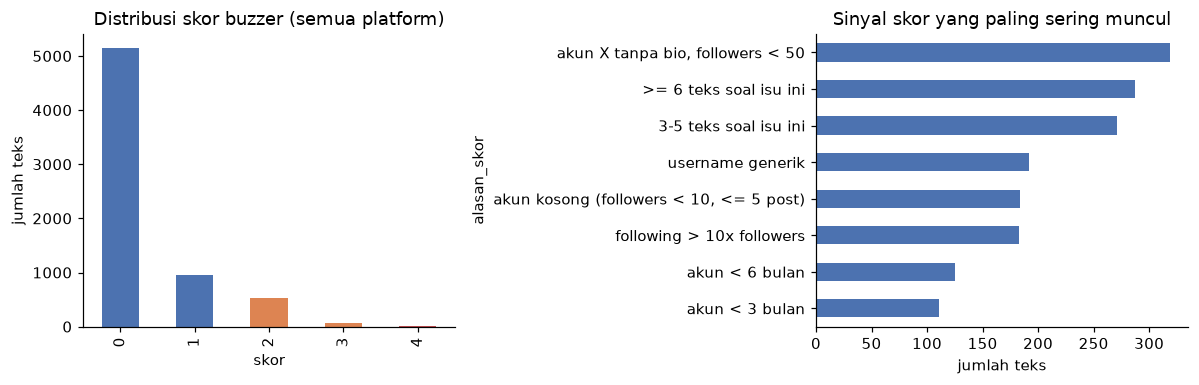

Distribusi skor: {0: 5146, 1: 958, 2: 524, 3: 71, 4: 10}

Sinyal skor terbanyak:
alasan_skor
akun X tanpa bio, followers < 50           319
>= 6 teks soal isu ini                     287
3-5 teks soal isu ini                      271
username generik                           192
akun kosong (followers < 10, <= 5 post)    184
following > 10x followers                  183
akun < 6 bulan                             125
akun < 3 bulan                             111

Aturan keras:
aturan_keras
akun X dibuat < 30 hari sebelum posting            13
satu akun memposting teks hampir sama >= 3 kali     7
narasi sama ditulis 3 akun                          2
narasi sama ditulis 4 akun                          2
narasi sama ditulis 6 akun                          1
narasi sama ditulis 11 akun                         1


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df.skor_buzzer.value_counts().sort_index().plot.bar(ax=ax[0], color=["#4C72B0"] * 2 + ["#DD8452"] * 2 + ["#C44E52"] * 20)
ax[0].set(title="Distribusi skor buzzer (semua platform)", xlabel="skor", ylabel="jumlah teks")
alasan = df[df.alasan_skor.ne("") & ~df.is_media].alasan_skor.str.split("; ").explode().value_counts().head(8)
alasan.sort_values().plot.barh(ax=ax[1], color="#4C72B0")
ax[1].set(title="Sinyal skor yang paling sering muncul", xlabel="jumlah teks")
plt.tight_layout()
plt.savefig(FIG / "f01_skor_buzzer.png", bbox_inches="tight")
plt.show()
print("Distribusi skor:", df.skor_buzzer.value_counts().sort_index().to_dict())
print()
print("Sinyal skor terbanyak:")
print(alasan.to_string())
print()
print("Aturan keras:")
print(df.aturan_keras.value_counts().to_string())

Sebagian besar teks (5.146) punya skor 0, lalu 958 skor 1, 524 skor 2, 71 skor 3, dan hanya 10 yang mencapai skor 4. Sinyal yang paling sering muncul adalah akun X tanpa bio dengan followers di bawah 50 (319 teks), disusul akun yang memposting 6 teks atau lebih (287) dan 3 sampai 5 teks (271) soal isu ini. Sinyal posting berulang ini wajar muncul di X, karena orang yang sedang kesal memang bisa membalas banyak tweet sekaligus. Jadi sinyal ini hanya berbobot 1 sampai 2 dan tidak bisa berdiri sendiri.

Untuk aturan keras, yang paling banyak adalah akun X yang dibuat kurang dari 30 hari sebelum posting (13 teks), lalu flooding teks hampir sama (7) dan narasi seragam dari banyak akun (6 klaster).

In [13]:
kolom_tampil = ["platform", "skor_buzzer", "alasan_skor", "text"]
print("Contoh skor tinggi (dikeluarkan):")
display(df[df.status_buzzer.eq("skor_tinggi")][kolom_tampil].sample(min(6, (df.status_buzzer == "skor_tinggi").sum()), random_state=1))
print("Contoh zona batas (ikut dilabeli, diputuskan saat review):")
display(df[df.status_buzzer.eq("batas")][kolom_tampil].sample(6, random_state=1))

Contoh skor tinggi (dikeluarkan):


,platform,skor_buzzer,alasan_skor,text
1305,x,4,following > 10x followers; username generik; >= 6 teks soal isu ini,"@user Semua circle nya gibran bakal stres raffi ahmad, hotman paris, influencer2 yg suka pamer2 itu, soalnya kapolri..."
2189,x,4,"akun X tanpa bio, followers < 50; akun < 3 bulan; >= 3 hashtag",INSYAF AA RAFI UDAH KAYA KAN? NGEJAR APE LAGI #socialexperiment #raffiahmad #kritik #publik #cfd
1555,x,4,following > 10x followers; username generik; >= 6 teks soal isu ini,"@user Mantap dia tanpa APBN bisa promosi indonesia ke mancanegara, raffi ahmad pake APBN 14,7 M cuma jalan2"
1311,x,4,following > 10x followers; username generik; >= 6 teks soal isu ini,"@user @user Raffi ahmad kan pejabat pemerintah, kpk harus turun nangkap raffi ahmad"
809,x,4,"akun X tanpa bio, followers < 50; akun < 3 bulan; >= 3 hashtag","Di tengah sorotan netizen terkait polemik mahasiswa palsu, Raffi Ahmad mengunggah video lawas Olga Syahputra tentang..."
1310,x,4,following > 10x followers; username generik; >= 6 teks soal isu ini,"@user @user Bukan boikot, raffi ahmad pejabat negara, tekan polisi atau kejaksaan, atau kpk buat mengusut si raffi a..."


Contoh zona batas (ikut dilabeli, diputuskan saat review):


,platform,skor_buzzer,alasan_skor,text
1532,x,3,akun < 3 bulan; 3-5 teks soal isu ini,@user ngalahin raffi ahmad dia ya😭😭
1218,x,3,"akun X tanpa bio, followers < 50; akun < 3 bulan",Akhirnya bisa belanja di Alfa lagi. Kemaren2 gua bela-belain jalan lebih jauh buat ke Indomart soalnya males ke Alfa...
221,x,2,>= 6 teks soal isu ini,"VISIONER BANGET KOMIKA INI. NONTON RIDWAN REMIN NGEROASTING PRABOWO, NIATNYA KETAWA, MALAH SPEECHLESS DAN BERLINANG ..."
1658,x,2,"akun X tanpa bio, followers < 50; akun < 6 bulan",@user kita patungan 2k perorang sisanya raffi ahmad kan duitnya dia duit rakyat☝️
5951,youtube,2,akun < 3 bulan,"Sy suka chanel nya mas bimo, sukses selalu mas bimo.. 👍"
4647,youtube,2,akun < 3 bulan,Kereen...Terus boikot si Rafi


Contoh skor tinggi semuanya dari X. Setelah saya cek author_hash-nya, 6 dari 10 teks skor tinggi berasal dari satu akun yang sama: following jauh lebih banyak dari followers, username generik, dan memposting balasan berulang dengan pola yang sama, yaitu membandingkan Raffi yang "pakai APBN 14,7 M cuma jalan-jalan" dengan kreator lain, lalu mendesak KPK turun. Pola ini cocok dengan akun yang dipakai khusus untuk satu isu.

Zona batas lebih beragam. Ada yang jelas mencurigakan, misalnya akun yang berkali-kali memposting template "Peringatan darurat Gerakan #indonesiasadar". Tapi ada juga yang kelihatannya orang biasa dengan akun sepi, misalnya "Hidung pinokio". Karena itulah zona batas tidak langsung dibuang, tapi diputuskan bersama penilaian isi dari annotator dan review manusia.

In [14]:
keluar = df.status_buzzer.isin(["keras", "skor_tinggi"])
buzzer = df[keluar].copy()
buang(keluar, "7. buzzer", np.where(df.aturan_keras.notna(), "aturan keras: " + df.aturan_keras.fillna(""),
                                     "skor buzzer >= 4: " + df.alasan_skor))
catat("7. buzzer")

7. buzzer                           dibuang    36, sisa 6673


Total 36 teks dikeluarkan sebagai buzzer (26 aturan keras dan 10 skor tinggi), dan 32 di antaranya dari X. Jumlah ini kecil dibanding total data. Saringan berikutnya untuk zona batas ada di tahap labeling dan review.

### Rincian alasan buzzer per teks

Dosen meminta alasan setiap teks dianggap buzzer ditulis jelas. Tabel di bawah memuat semua teks yang dikeluarkan di tahap ini beserta alasannya. Ringkasan dasar tiap alasan:

| alasan | jenis | dasar |
|---|---|---|
| akun X dibuat < 30 hari sebelum posting | aturan keras | tanggal pembuatan akun (`author.createdAt`) dibandingkan dengan tanggal tweet. Akun yang baru dibuat menjelang kasus lalu langsung membahas kasus adalah pola akun kampanye |
| akun ditandai otomatis oleh X | aturan keras | field `isAutomated` dari X |
| narasi sama ditulis >= 3 akun | aturan keras | teks minimal 5 kata dengan kemiripan cosine karakter >= 0,85 (radius 0,15) ditulis oleh 3 akun berbeda atau lebih |
| satu akun memposting teks hampir sama >= 3 kali | aturan keras | klaster teks yang sama dari `author_hash` yang sama muncul 3 kali atau lebih (flooding) |
| skor >= 4 | skor poin | penjumlahan sinyal lemah di fungsi `skor_buzzer`: akun baru (< 3 atau < 6 bulan), following > 10x followers, username generik, akun kosong, > 100 tweet per hari, >= 3 atau >= 6 teks soal isu ini, teks mirip dengan akun lain, >= 3 hashtag |

Selain itu ada lapis ketiga yang tidak terlihat di notebook ini, yaitu penilaian dari isi teks oleh annotator dan review manusia untuk teks zona batas (skor 2 sampai 3). Hasil lapis ketiga dicatat di `labeling/finalize.py` dan dibahas di laporan.

In [15]:
rinci = buzzer.assign(alasan=np.where(buzzer.aturan_keras.notna(), "aturan keras: " + buzzer.aturan_keras.fillna(""),
                                      "skor " + buzzer.skor_buzzer.astype(str) + ": " + buzzer.alasan_skor))
print(rinci.alasan.str.split(":").str[0].value_counts().to_string())
rinci[["platform", "alasan", "n_teks_akun", "text"]].sort_values("alasan")

alasan
aturan keras    26
skor 4          10


,platform,alasan,n_teks_akun,text
18,x,aturan keras: akun X dibuat < 30 hari sebelum posting,2,"Ini dia beberapa orang kaya di Indonesia pemilik Rolls Royce. Salah satunya Raffi Ahmad, yang memiliki Rolls Royce P..."
22,x,aturan keras: akun X dibuat < 30 hari sebelum posting,1,@user kalo emg lu sakti kenapa ilmunya kaga lu praktekin aja buat diri lu? jadiin lah karir lu minimal setara rafi a...
1487,x,aturan keras: akun X dibuat < 30 hari sebelum posting,1,info A1 katanya si raffi ahmad dan sekeluarga mau ngungsi ke singapura 🤔
140,x,aturan keras: akun X dibuat < 30 hari sebelum posting,1,"@user terus ntar para orang2 yang ""pemaaf"" dan gampang banget kehasut itu pasti bakal makin muji2 si rappi ini ""wah ..."
499,x,aturan keras: akun X dibuat < 30 hari sebelum posting,2,"Recap: 1. Karhutla belum tuntas. 2. Banner kuning di bundaran HI. 3. Raffi, Willie, dan mahasiswa palsu. 4. Karnival..."
1461,x,aturan keras: akun X dibuat < 30 hari sebelum posting,1,@user Segede punya Rafi Ahmad
868,x,aturan keras: akun X dibuat < 30 hari sebelum posting,1,@user mau jadi rafi ahmad
1669,x,aturan keras: akun X dibuat < 30 hari sebelum posting,1,@user Ini jauh LBH keren drpd si Raffi ahmad
901,x,aturan keras: akun X dibuat < 30 hari sebelum posting,2,🚨BREAKING NEWS🚨 DIHUJAT MAKIN JATUH ❎ DIHUJAT MAKIN BERSINAR✅ Raffi Ahmad kabarnya memperluas sayap bisnisnya dengan...
1912,x,aturan keras: akun X dibuat < 30 hari sebelum posting,1,"14M buat endorse raffi ahmad, reels perdetik 500jt tapi sekolah di pelosok masih gubug dan gak layak huni, ini yang ..."


Ke-36 teks buzzer terdiri dari 26 teks yang kena aturan keras dan 10 teks dengan skor 4. Sebanyak 32 dari X, karena hanya X yang memberi umur akun dan jumlah tweet. Daftar ini sama persis dengan versi pertama, jadi revisi gerbang 2 sampai 5 tidak mengubah siapa yang dianggap buzzer.

Ada satu hal yang perlu dicatat jujur. Aturan "narasi sama ditulis >= 3 akun" ikut menangkap meme "Sultan andara ANGGARAN DARI NEGARA" (11 akun). Di bagian duplikat di atas saya sendiri menilai ini meme yang ditiru banyak orang, bukan narasi pesanan. Jadi aturan ini bisa salah untuk lelucon yang viral. Dampaknya kecil karena yang dikeluarkan hanya satu teks wakil klaster (salinannya sudah dibuang di tahap duplikat), tapi teks ini tetap saya tandai sebagai kemungkinan salah tangkap di laporan.

## 8. Membatasi dominasi satu sumber

Unggahan atau video yang sangat viral bisa menyumbang ratusan komentar, sehingga hasil sentimen lebih menggambarkan satu kolom komentar daripada publik secara umum. Saat scraping saya sudah membatasi 100 komentar per unggahan IG, 100 per video YouTube, dan 60 per video TikTok. Untuk X, satu thread (conversation) saya batasi maksimal 25 tweet. Yang dipertahankan adalah tweet dengan like terbanyak.

In [16]:
df = df.sort_values("like_count", ascending=False)
df["urut_sumber"] = df.groupby(["platform", "sumber_id"]).cumcount()
buang((df.platform == "x") & (df.urut_sumber >= 25), "8. batas per thread X", "thread X > 25 tweet")
catat("8. batas per sumber")
df.groupby("platform").sumber_id.nunique().rename("jumlah sumber").to_frame()

8. batas per thread X               dibuang     0, sisa 6673


,jumlah sumber
platform,
instagram,30
tiktok,14
x,1868
youtube,20


Tidak ada thread X yang lebih dari 25 tweet setelah filter, jadi tahap ini tidak membuang apa pun. Data akhirnya berasal dari 30 unggahan Instagram, 14 video TikTok, 20 video YouTube, dan 1.846 thread X yang berbeda. X sangat tersebar karena tiap tweet kebanyakan berdiri sendiri.

## 9. Sampling bertingkat untuk dilabeli

Setelah semua filter, jalur A masih berisi sekitar 6 ribu teks, jauh di atas target sekitar 3.500 yang kami sepakati supaya beban review manusia tetap masuk akal. Karena itu saya mengambil sampel bertingkat (stratified sampling) dengan target per platform: X 1.300, Instagram 900, YouTube 800, dan TikTok 500. X lebih banyak karena hanya X yang punya data di fase pra dan sebaran harinya paling merata. Sampelnya diambil acak di dalam setiap strata (tanggal untuk X, unggahan atau video untuk platform lain), bukan berdasarkan like terbanyak, supaya komentar biasa tetap terwakili. Semua tweet fase pra diambil karena jumlahnya kecil.

**Sampel versi pertama dibekukan.** Sampel versi pertama (3.498 teks) sudah dilabeli tiga annotator dan direview lima orang. Kalau sampling diulang dari awal di data yang sekarang sedikit lebih banyak, `random_state` yang sama tetap akan menghasilkan sampel yang berbeda, jadi semua label harus diulang. Karena itu ID sampel versi pertama disimpan di `audit/sampel_v1.csv` dan dipakai lagi apa adanya.

**Teks baru diambil dengan rasio yang sama.** Teks yang baru lolos karena revisi gerbang (tidak ada di sampel maupun cadangan versi pertama) diambil dengan peluang yang sama dengan rasio sampling versi pertama di platformnya. Misalnya kalau versi pertama mengambil 54% teks YouTube, setiap teks YouTube baru juga punya peluang 54% untuk terambil. Dengan begitu proporsi per platform tetap sama seperti kalau teks itu sudah ada sejak awal. Tweet fase pra tetap diambil semua.

In [17]:
v1 = pd.read_csv(AUDIT / "sampel_v1.csv", dtype=str)
a_all = df[df.jalur.eq("A")]
pool_v1 = v1[v1.status_v1.isin(["sampel_A", "cadangan_A"])]
tetap = a_all[a_all.id.isin(v1.id[v1.status_v1.eq("sampel_A")])]
baru = a_all[~a_all.id.isin(pool_v1.id)]

# rasio sampling versi pertama per platform (tweet fase pra tidak dihitung karena selalu diambil semua)
bukan_pra = pool_v1[pool_v1.fase.ne("pra")]
rasio = bukan_pra.groupby("platform").status_v1.apply(lambda s: s.eq("sampel_A").mean())
rng = np.random.default_rng(42)
ambil = baru.fase.eq("pra") | (rng.random(len(baru)) < baru.platform.map(rasio).values)
terpilih = pd.concat([tetap, baru[ambil.values]])
cadangan = a_all.drop(terpilih.index)

hilang = v1[v1.status_v1.eq("sampel_A") & ~v1.id.isin(a_all.id)]
print("rasio sampling versi pertama:", rasio.round(3).to_dict())
print("sampel versi pertama yang tetap:", len(tetap), "| hilang dari jalur A:", len(hilang))
print("teks baru:", len(baru), baru.platform.value_counts().to_dict(), "| terambil:", int(ambil.sum()))
print("terpilih:", terpilih.platform.value_counts().to_dict())
print("cadangan:", len(cadangan), cadangan.platform.value_counts().to_dict())
df = pd.concat([terpilih, df[df.jalur.eq("B")]])
catat("9. sampel untuk dilabeli")

rasio sampling versi pertama: {'instagram': 0.713, 'tiktok': 0.605, 'x': 0.635, 'youtube': 0.403}
sampel versi pertama yang tetap: 3498 | hilang dari jalur A: 0
teks baru: 49 {'x': 24, 'instagram': 19, 'youtube': 4, 'tiktok': 2} | terambil: 27
terpilih: {'x': 1314, 'instagram': 909, 'youtube': 801, 'tiktok': 501}
cadangan: 2623 {'youtube': 1185, 'x': 742, 'instagram': 370, 'tiktok': 326}


Rasio sampling versi pertama adalah 71,3% untuk Instagram, 60,5% TikTok, 63,5% X, dan 40,3% YouTube. Semua 3.498 teks sampel versi pertama masih lolos filter, jadi tidak ada label lama yang terbuang. Revisi gerbang menghasilkan 49 teks baru di jalur A, dan 27 di antaranya terambil dengan rasio tersebut. Sampel sekarang berisi X 1.314, Instagram 909, YouTube 801, dan TikTok 501. Sisanya, 2.623 teks, masuk ke cadangan dan paling banyak berasal dari YouTube (1.185).

## Ringkasan corong data

,x,instagram,youtube,tiktok,total
tahap,,,,,
0. mentah (setelah buang ID kembar),2197,1989,2000,834,7020
1. rentang tanggal,2197,1989,2000,834,7020
2. pemilik unggahan,2197,1975,1998,834,7004
3. tanpa isi,2197,1832,1992,833,6854
4. bahasa & spam,2191,1832,1992,833,6848
5. relevansi X,2131,1832,1992,833,6788
6. duplikat,2088,1807,1987,827,6709
7. buzzer,2056,1804,1986,827,6673
8. batas per sumber,2056,1804,1986,827,6673


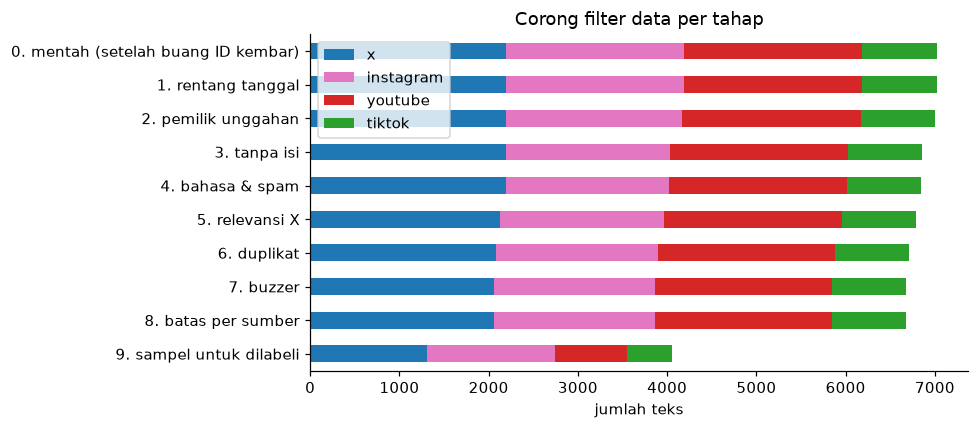

In [18]:
corong_df = pd.DataFrame(corong).fillna(0).set_index("tahap").astype(int)
corong_df = corong_df[["x", "instagram", "youtube", "tiktok", "total"]]
display(corong_df)

fig, ax = plt.subplots(figsize=(9, 4))
corong_df.drop(columns="total").iloc[::-1].plot.barh(stacked=True, ax=ax, color=["#1f77b4", "#e377c2", "#d62728", "#2ca02c"])
ax.set(title="Corong filter data per tahap", xlabel="jumlah teks", ylabel="")
plt.tight_layout()
plt.savefig(FIG / "f02_corong_filter.png", bbox_inches="tight")
plt.show()

Dari 7.020 teks mentah, 6.673 lolos semua filter dan 4.050 diambil untuk dilabeli (3.525 jalur A dan 525 jalur B). Di versi pertama yang lolos 6.612, jadi revisi gerbang menyelamatkan 61 teks. Tahap yang paling banyak membuang sekarang adalah teks tanpa isi (150), disusul duplikat (79) dan relevansi X (60). Tahap bahasa dan spam yang dulu membuang 27 teks sekarang hanya membuang 6.

## Simpan hasil

Hasil filter dipisah menjadi empat berkas di `data/03_filtered/`:

- `dataset_untuk_label.csv`: jalur A (X, IG publik, YouTube, TikTok) yang lolos semua filter. Ini yang dilabeli 3 annotator dan nanti dipakai untuk training.
- `jalur_b_untuk_label.csv`: komentar di akun Raffi sendiri yang lolos filter. Ikut dilabeli, tapi hanya untuk analisis pembanding.
- `buzzer.csv`: teks yang dikeluarkan oleh filter buzzer, beserta alasannya. Ikut dilabeli supaya sikap buzzer bisa dilaporkan terpisah.
- `cadangan_belum_dilabel.csv`: teks jalur A yang lolos filter tapi tidak terambil sampel. Tidak dilabeli, nanti diprediksi model.
- `dibuang.csv`: semua teks yang dibuang di tahap 1 sampai 8, dengan tahap dan alasannya.
- `audit/keputusan_manual.csv`: keputusan manual per kandidat gerbang 2, 4a, 4b, dan 5, beserta alasannya.
- `audit/hasil_cek_manual.csv`: semua kandidat yang diperiksa, lengkap dengan teks dan keputusannya.
- `audit/sampel_v1.csv`, `audit/dibuang_v1.csv`: ID sampel dan daftar buang versi pertama, untuk pembanding.
- `audit/perlu_label_v2.csv`: teks yang baru masuk karena revisi gerbang dan belum pernah dilabeli.

In [19]:
simpan = ["id", "platform", "jalur", "fase", "tanggal", "created_at", "sumber_id", "sumber_url", "konteks", "text",
          "text_raw", "is_reply", "like_count", "author_hash", "is_media", "is_pemilik_sumber", "skor_buzzer", "alasan_skor",
          "status_buzzer", "n_teks_akun", "n_akun_teks_mirip"]
a = df[df.jalur.eq("A")][simpan].sort_values("created_at")
b = df[df.jalur.eq("B")][simpan].sort_values("created_at")
a.to_csv(OUT / "dataset_untuk_label.csv", index=False, encoding="utf-8-sig")
b.to_csv(OUT / "jalur_b_untuk_label.csv", index=False, encoding="utf-8-sig")
buzzer[simpan + ["aturan_keras"]].to_csv(OUT / "buzzer.csv", index=False, encoding="utf-8-sig")
cadangan[simpan].to_csv(OUT / "cadangan_belum_dilabel.csv", index=False, encoding="utf-8-sig")
semua_buang = pd.concat(dibuang, ignore_index=True)
semua_buang[["id", "platform", "jalur", "tahap", "alasan", "text_raw"]].to_csv(OUT / "dibuang.csv", index=False, encoding="utf-8-sig")
corong_df.to_csv(OUT / "corong_filter.csv", encoding="utf-8-sig")
pd.concat([cek2.assign(gerbang="2"), cek4a.assign(gerbang="4a"), cek4b.assign(gerbang="4b"), cek5.assign(gerbang="5")]
          ).to_csv(AUDIT / "hasil_cek_manual.csv", index=False, encoding="utf-8-sig")

# teks yang belum pernah dilabeli (baru masuk karena revisi gerbang)
sudah = set(pd.read_csv(ROOT / "labeling" / "batches" / "index.csv", dtype=str).id)
perlu_label = pd.concat([a.assign(kelompok="utama"), b.assign(kelompok="jalur_b"), buzzer[simpan].assign(kelompok="buzzer")])
perlu_label = perlu_label[~perlu_label.id.isin(sudah)].drop_duplicates("id")
perlu_label.to_csv(AUDIT / "perlu_label_v2.csv", index=False, encoding="utf-8-sig")

print("jalur A:", len(a), a.platform.value_counts().to_dict())
print("jalur A zona batas buzzer:", int(a.status_buzzer.eq("batas").sum()), "| akun media:", int(a.is_media.sum()),
      "| pemilik unggahan:", int(a.is_pemilik_sumber.astype(bool).sum()))
print("jalur B:", len(b), "| cadangan belum dilabel:", len(cadangan))
print("buzzer:", len(buzzer), buzzer.jalur.value_counts().to_dict())
print("dibuang:", len(semua_buang))
print("belum pernah dilabeli:", len(perlu_label), perlu_label.kelompok.value_counts().to_dict())
pd.crosstab(a.fase, a.platform, margins=True)

jalur A: 3525 {'x': 1314, 'instagram': 909, 'youtube': 801, 'tiktok': 501}
jalur A zona batas buzzer: 341 | akun media: 138 | pemilik unggahan: 7
jalur B: 525 | cadangan belum dilabel: 2623
buzzer: 36 {'A': 34, 'B': 2}
dibuang: 347
belum pernah dilabeli: 39 {'utama': 27, 'jalur_b': 12}


platform,instagram,tiktok,x,youtube,All
fase,,,,,
pasca,424,227,975,179,1805
pra,0,0,31,0,31
puncak,485,274,308,622,1689
All,909,501,1314,801,3525


Data jalur A yang siap dilabeli berisi 3.525 teks. Di dalamnya ada 341 teks zona batas buzzer, 138 teks dari akun media di X, dan 7 teks dari pemilik unggahan yang dipertahankan (5 teks pemilik unggahan lainnya tidak terambil sampel dan masuk cadangan). Jalur B berisi 525 komentar, buzzer 36 teks, dan teks yang dibuang 347. Ada 39 teks yang belum pernah dilabeli (27 jalur A dan 12 jalur B). Teks ini dilabeli tiga annotator yang sama dengan codebook yang sama, sebagai batch tambahan.

## Kesimpulan

Dari 7.020 teks mentah, 4.050 teks siap dilabeli: 3.525 di jalur A untuk training dan analisis utama, dan 525 di jalur B (akun Raffi) untuk pembanding. Sebanyak 2.623 teks yang lolos filter tapi tidak terambil sampel disimpan sebagai cadangan untuk diprediksi model.

Hal yang paling berpengaruh di revisi ini adalah pemeriksaan manual setiap kandidat buang. Aturan otomatis di versi pertama ternyata overklaim di hampir semua gerbang: 12 dari 28 teks pemilik unggahan berisi opini, 14 dari 20 tweet "berbahasa asing" ternyata berbahasa Indonesia, dan 10 dari 10 teks "spam" ternyata opini. Huruf unicode bergaya juga membuat teks relevan terbuang. Setelah semua kandidat dibaca, 61 teks diselamatkan.

Hal kedua adalah kalibrasi filter buzzer. Dengan bobot yang sama untuk semua platform, 78% komentar YouTube masuk zona batas hanya karena penonton YouTube memang punya channel kosong. Setelah sinyal profil dibedakan per platform, zona batas tinggal 580 teks dan lebih banyak berisi akun yang memang aktif menyebar narasi yang sama.

Keterbatasannya ada tiga. Pertama, fase pra hanya punya 31 tweet, jadi perbandingan sebelum dan sesudah kasus tidak bisa dibuat kuat. Kedua, Instagram dan TikTok tidak memberi tanggal pembuatan akun, sehingga filter buzzer di dua platform ini lebih lemah dibanding X. Ketiga, ada 5 balasan X yang mungkin relevan tapi terbuang karena tweet induknya tidak ikut ter-scrape, dan aturan narasi seragam bisa salah menangkap meme viral.